## Exploracao dos dados sobre AVC 


In [25]:
import pandas as pd
import matplotlib.pyplot as plt

In [5]:
df = pd.read_csv("../data/raw/healthcare-dataset-stroke-data.csv")
df.head()

,id,gender,age,hypertension,heart_disease,ever_married,work_type,Residence_type,avg_glucose_level,bmi,smoking_status,stroke
0,9046,Male,67.0,0,1,Yes,Private,Urban,228.69,36.6,formerly smoked,1
1,51676,Female,61.0,0,0,Yes,Self-employed,Rural,202.21,NaN,never smoked,1
2,31112,Male,80.0,0,1,Yes,Private,Rural,105.92,32.5,never smoked,1
3,60182,Female,49.0,0,0,Yes,Private,Urban,171.23,34.4,smokes,1
4,1665,Female,79.0,1,0,Yes,Self-employed,Rural,174.12,24.0,never smoked,1


In [8]:
print("Quantidade de linhas no dataset: ", df.shape[0])
print("Quantidade de colunas no dataset: ", df.shape[1])

Quantidade de linhas no dataset:  5110
Quantidade de colunas no dataset:  12


In [12]:
print(df.columns.tolist())
print("**************************")
print(df.dtypes)

['id', 'gender', 'age', 'hypertension', 'heart_disease', 'ever_married', 'work_type', 'Residence_type', 'avg_glucose_level', 'bmi', 'smoking_status', 'stroke']
**************************
id                     int64
gender                   str
age                  float64
hypertension           int64
heart_disease          int64
ever_married             str
work_type                str
Residence_type           str
avg_glucose_level    float64
bmi                  float64
smoking_status           str
stroke                 int64
dtype: object


In [18]:

df[df.isna().any(axis=1)]

,id,gender,age,hypertension,heart_disease,ever_married,work_type,Residence_type,avg_glucose_level,bmi,smoking_status,stroke
1,51676,Female,61.0,0,0,Yes,Self-employed,Rural,202.21,NaN,never smoked,1
8,27419,Female,59.0,0,0,Yes,Private,Rural,76.15,NaN,Unknown,1
13,8213,Male,78.0,0,1,Yes,Private,Urban,219.84,NaN,Unknown,1
19,25226,Male,57.0,0,1,No,Govt_job,Urban,217.08,NaN,Unknown,1
27,61843,Male,58.0,0,0,Yes,Private,Rural,189.84,NaN,Unknown,1
...,...,...,...,...,...,...,...,...,...,...,...,...
5039,42007,Male,41.0,0,0,No,Private,Rural,70.15,NaN,formerly smoked,0
5048,28788,Male,40.0,0,0,Yes,Private,Urban,191.15,NaN,smokes,0
5093,32235,Female,45.0,1,0,Yes,Govt_job,Rural,95.02,NaN,smokes,0
5099,7293,Male,40.0,0,0,Yes,Private,Rural,83.94,NaN,smokes,0


In [21]:
print(df.isna().sum())
print(df.duplicated().sum())

id                     0
gender                 0
age                    0
hypertension           0
heart_disease          0
ever_married           0
work_type              0
Residence_type         0
avg_glucose_level      0
bmi                  201
smoking_status         0
stroke                 0
dtype: int64
0


In [24]:
df["stroke"].value_counts()

stroke
0    4861
1     249
Name: count, dtype: int64

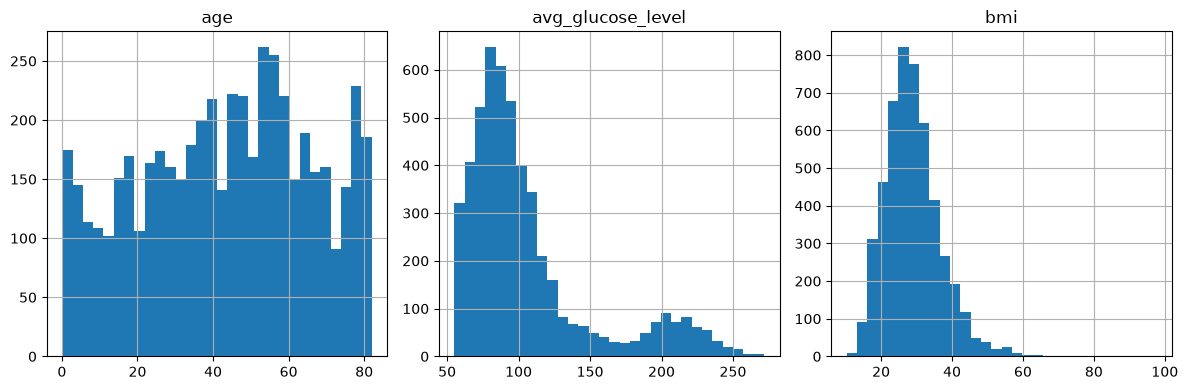

In [26]:
colunas = ["age", "avg_glucose_level", "bmi"]

df[colunas].hist(bins=30, figsize=(12, 4), layout=(1, 3))
plt.tight_layout()
plt.show()

In [27]:
df[colunas].describe()

,age,avg_glucose_level,bmi
count,5110.000000,5110.000000,4909.000000
mean,43.226614,106.147677,28.893237
std,22.612647,45.283560,7.854067
min,0.080000,55.120000,10.300000
25%,25.000000,77.245000,23.500000
50%,45.000000,91.885000,28.100000
75%,61.000000,114.090000,33.100000
max,82.000000,271.740000,97.600000


In [29]:
for col in ["gender", "work_type", "smoking_status"]:
    print(f"{col}: {df[col].unique()}\n")


gender: <StringArray>
['Male', 'Female', 'Other']
Length: 3, dtype: str

work_type: <StringArray>
['Private', 'Self-employed', 'Govt_job', 'children', 'Never_worked']
Length: 5, dtype: str

smoking_status: <StringArray>
['formerly smoked', 'never smoked', 'smokes', 'Unknown']
Length: 4, dtype: str



In [31]:
df["id"].duplicated().sum()

np.int64(0)

In [32]:
resultado = (
    df.assign(bmi_ausente=df["bmi"].isna())
    .groupby("stroke")["bmi_ausente"]
    .agg(ausentes="sum", total="size", proporcao="mean")
)

resultado["percentual"] = resultado["proporcao"] * 100

resultado

,ausentes,total,proporcao,percentual
stroke,,,,
0,161,4861,0.033121,3.312076
1,40,249,0.160643,16.064257


In [33]:
(df["smoking_status"] == "Unknown").sum()

np.int64(1544)